# Analisis LOGIKA UI 2026

Notebook ini membaca hasil analisis yang telah dijalankan. Gunakan `python scripts/analyze.py` untuk membangun ulang seluruh tabel, fitur, dan baseline. Definisi data tersedia pada `data/raw/DATA_DICTIONARY.md`. Kredensial tidak diperlukan untuk membaca hasil lokal.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'artifacts').exists():
    ROOT = ROOT.parent
ART = ROOT / 'artifacts'
summary = json.loads((ART / 'summary.json').read_text())
features = pd.read_parquet(ROOT / 'data/processed/application_features.parquet')
train = features[features['split'].eq('train')].copy()
test = features[features['split'].eq('test')].copy()
display(pd.Series({k: v for k, v in summary.items() if k not in ['benchmarks', 'top_model_gain_features', 'versions']}))

generated_at_utc                          2026-10-12T13:09:07.164618+00:00
train_rows                                                           70000
test_rows                                                            30000
defaults                                                              9507
default_rate                                                      0.135814
majority_accuracy                                                 0.864186
total_raw_rows                                                     8035123
raw_size_mb                                                     948.798474
feature_columns                                                        116
naive_ecommerce_spend_inflation_factor                            1.739617
max_train_test_ks                                                 0.014424
max_absolute_smd                                                  0.027254
dtype: object

## Struktur dan kualitas

Nilai kosong struktural, misalnya pinjaman ditolak atau utilization tanpa limit, mempunyai arti berbeda dari nol.

In [2]:
display(pd.read_csv(ART / 'tables/table_inventory.csv'))
display(pd.read_csv(ART / 'tables/history_coverage.csv'))
quality = pd.read_csv(ART / 'tables/column_quality.csv')
display(quality[quality['missing'].gt(0)])
audit = json.loads((ART / 'quality_audit.json').read_text())
display(audit)

,table,rows,columns,customers,size_mb
0,train_applications,70000,10,70000.0,8.218128
1,test_applications,30000,9,30000.0,3.462500
2,sample_submission,30000,2,NaN,0.780036
3,customer_profiles,100000,8,100000.0,6.415774
4,previous_applications,201984,11,70000.0,26.688010
5,repayment_history,1361341,9,66157.0,159.687932
6,account_behavior,1084418,10,70000.0,99.958562
7,bureau_observations,797563,14,100000.0,114.740593
8,ecommerce_transactions,4359817,10,100000.0,528.846939


,table,split,covered_customers,coverage_pct
0,train_applications,train,70000,100.00
1,train_applications,test,0,0.00
2,test_applications,train,0,0.00
3,test_applications,test,30000,100.00
4,customer_profiles,train,70000,100.00
5,customer_profiles,test,30000,100.00
6,previous_applications,train,49000,70.00
7,previous_applications,test,21000,70.00
8,repayment_history,train,46312,66.16
9,repayment_history,test,19845,66.15


,table,column,dtype,missing,missing_pct,unique_values
36,previous_applications,loan_id,object,42661,21.120980,159323
37,previous_applications,approved_amount,float64,42661,21.120980,1383
38,previous_applications,annual_interest_rate,float64,42661,21.120980,5
39,previous_applications,scheduled_monthly_installment,float64,42661,21.120980,10468
46,repayment_history,last_payment_datetime,datetime64[ns],31714,2.329615,615249
65,bureau_observations,score,float64,43839,5.496619,403
70,bureau_observations,utilization,float64,471615,59.132006,325948


{'train_applications': {'duplicate_rows': 0,
  'duplicate_primary_keys': 0,
  'orphan_customers': 0},
 'test_applications': {'duplicate_rows': 0,
  'duplicate_primary_keys': 0,
  'orphan_customers': 0},
 'sample_submission': {'duplicate_rows': 0, 'duplicate_primary_keys': 0},
 'submission': {'same_id_set_as_test': True,
  'same_row_order_as_test': False,
  'target_column': 'default_probability'},
 'customer_profiles': {'duplicate_rows': 0,
  'duplicate_primary_keys': 0,
  'orphan_customers': 0},
 'applications': {'train_test_customer_overlap': 0,
  'train_test_application_overlap': 0,
  'decision_before_application': 0,
  'nonpositive_income': 0,
  'installment_formula_max_rounding_difference_idr': 1.0,
  'term_months_values': [12]},
 'previous_applications': {'duplicate_rows': 0,
  'duplicate_primary_keys': 0,
  'orphan_customers': 0,
  'overlap_with_selected_application_ids': 0,
  'application_datetime_at_or_after_cutoff': 0,
  'decision_datetime_at_or_after_cutoff': 0},
 'repayment_

## Target, waktu, dan asosiasi

Target 1 berarti mencapai DPD 90 dalam 12 bulan kalender. Asosiasi dan importance tidak membuktikan sebab akibat.

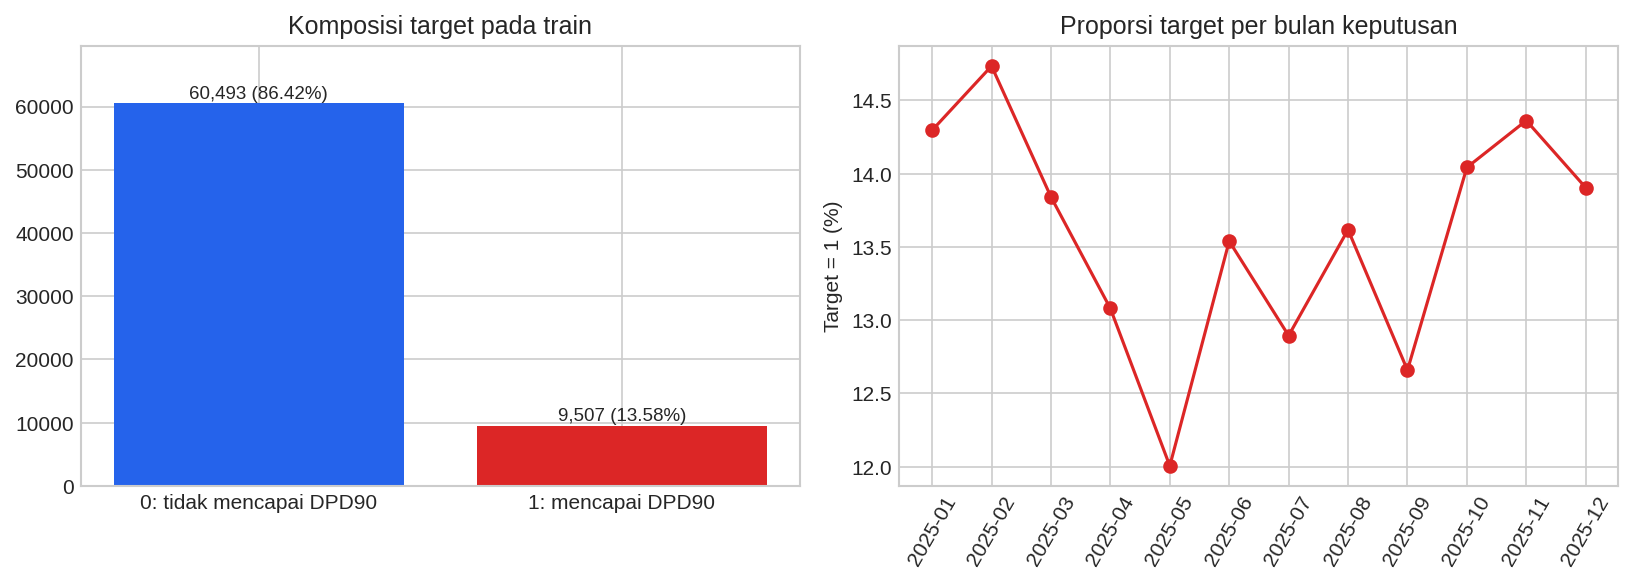

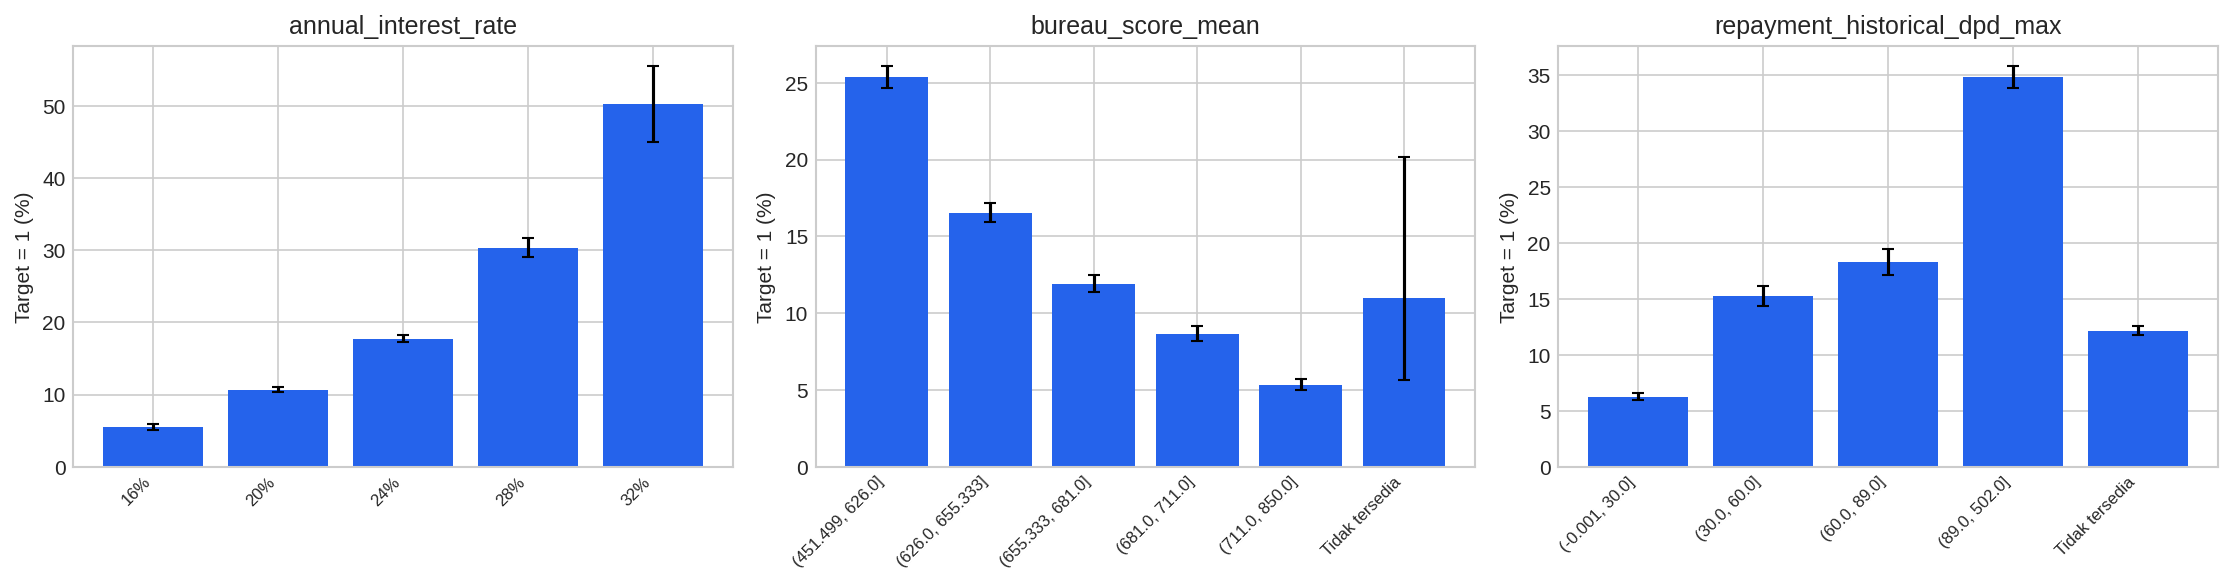

,group,n,defaults,default_rate,ci95_low,ci95_high,variable
0,0.16,12560,690.0,0.054936,0.051086,0.059059,annual_interest_rate
1,0.2,29800,3173.0,0.106477,0.103025,0.110029,annual_interest_rate
2,0.24,22358,3972.0,0.177655,0.172700,0.182720,annual_interest_rate
3,0.28,4938,1499.0,0.303564,0.290896,0.316537,annual_interest_rate
4,0.32,344,173.0,0.502907,0.450330,0.555419,annual_interest_rate


,feature,pearson_target_correlation,absolute_correlation
0,repayment_historical_dpd_mean,0.391250,0.391250
1,repayment_late_share,0.382035,0.382035
2,repayment_dpd30_share,0.381958,0.381958
3,repayment_historical_dpd_max,0.356711,0.356711
4,repayment_dpd_mean_180d,0.354365,0.354365
5,repayment_dpd90_share,0.329057,0.329057
6,repayment_current_dpd_max,0.317607,0.317607
7,repayment_paid_ratio,-0.282948,0.282948
8,repayment_unpaid_180d,0.240793,0.240793
9,repayment_unpaid_amount,0.236464,0.236464


In [3]:
display(Image(filename=str(ART / 'figures/target_and_time.png')))
display(Image(filename=str(ART / 'figures/risk_signals.png')))
risk = pd.read_csv(ART / 'tables/default_by_group.csv')
display(risk[risk['variable'].eq('annual_interest_rate')])
display(pd.read_csv(ART / 'tables/target_correlations.csv').head(15))

## Distribusi train dan test

Perbedaan marginal yang kecil tidak menjamin hubungan fitur-target identik. Label test tidak tersedia.

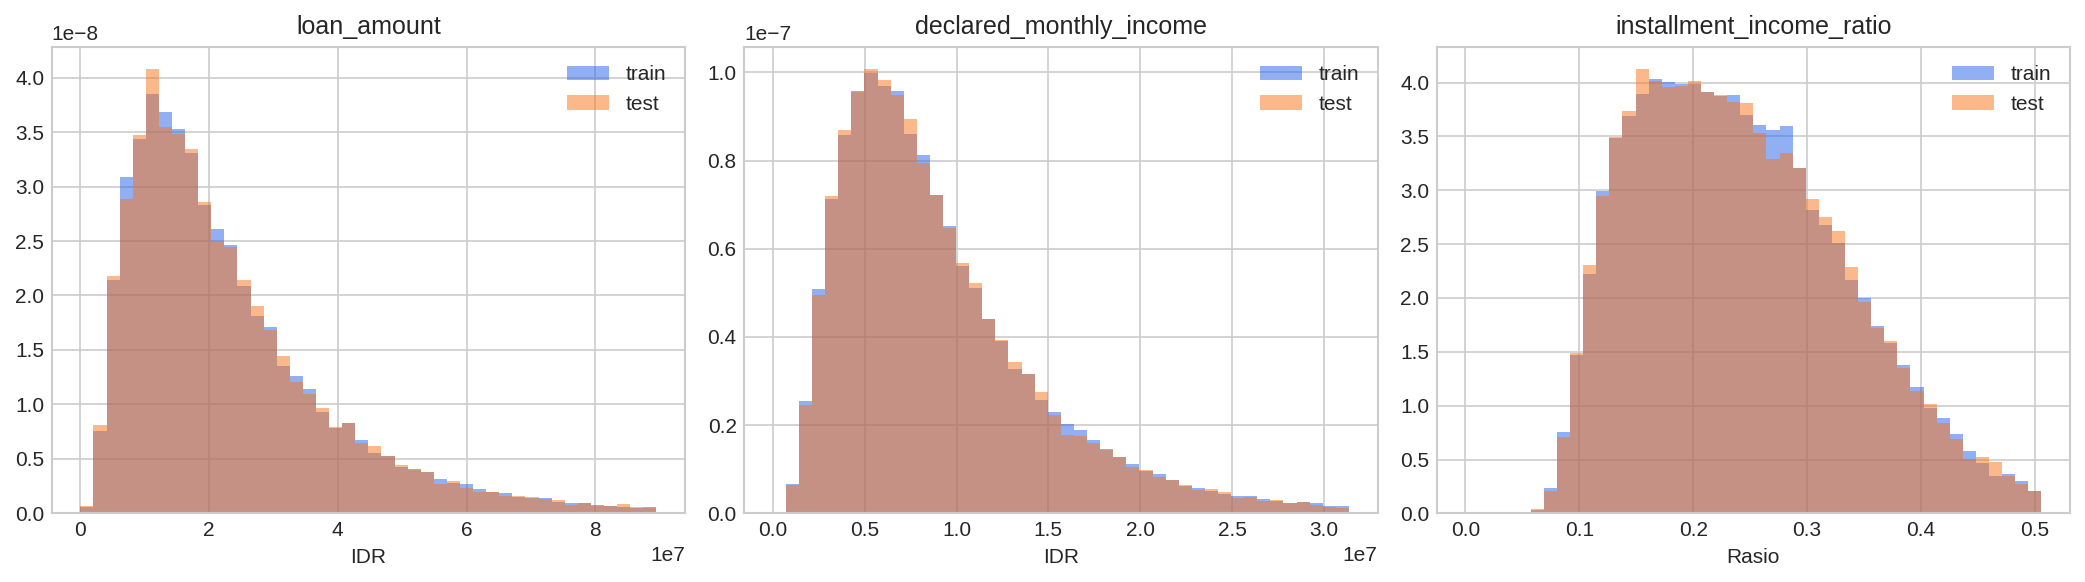

,feature,train_mean,test_mean,standardized_mean_difference,ks_statistic,train_missing_pct,test_missing_pct
0,bureau_Bureau_A_utilization,4.862708e-01,4.825986e-01,-0.023461,0.014424,56.922857,57.010000
1,bureau_Bureau_B_utilization,4.881398e-01,4.838983e-01,-0.027254,0.013978,61.262857,61.546667
2,account_last_closing_balance,6.237802e+07,6.202248e+07,-0.005223,0.011837,30.000000,30.000000
3,account_average_balance_mean,3.815363e+07,3.797340e+07,-0.004611,0.010986,30.000000,30.000000
4,bureau_inquiries_max,2.486371e+00,2.454500e+00,-0.025954,0.010933,0.000000,0.000000
5,account_last_average_balance,6.029164e+07,5.992216e+07,-0.005578,0.010830,30.000000,30.000000
6,bureau_utilization_max,5.470010e-01,5.434299e-01,-0.023897,0.010653,51.988571,52.066667
7,employment_tenure_months,5.141176e+01,5.206367e+01,0.019230,0.009876,0.000000,0.000000
8,account_balance_mean_3m,5.751610e+07,5.717110e+07,-0.005457,0.009844,30.000000,30.000000
9,bureau_Bureau_A_report_age_days,5.953710e+01,5.916032e+01,-0.010987,0.009710,0.000000,0.000000


,feature,train_missing_pct,test_missing_pct
84,bureau_Bureau_C_utilization,63.414286,63.486667
83,bureau_Bureau_B_utilization,61.262857,61.546667
82,bureau_Bureau_A_utilization,56.922857,57.010000
73,bureau_utilization_max,51.988571,52.066667
40,repayment_unpaid_180d,40.192857,40.170000
39,repayment_dpd_mean_180d,40.192857,40.170000
32,repayment_current_dpd_max,33.840000,33.850000
27,repayment_installment_count,33.840000,33.850000
28,repayment_loan_count,33.840000,33.850000
29,repayment_amount_due,33.840000,33.850000


In [4]:
display(Image(filename=str(ART / 'figures/train_test_distributions.png')))
display(pd.read_csv(ART / 'tables/train_test_numeric_drift.csv').head(15))
display(pd.read_csv(ART / 'tables/feature_missingness.csv').sort_values('train_missing_pct', ascending=False).head(20))

## Baseline dan kalibrasi

Parameter tetap; holdout stratified dan temporal. Metrik resmi adalah Kolmogorov-Smirnov (KS), sesuai Evaluation yang diberikan pengguna. Semua angka tabel ini adalah hasil lokal, bukan skor leaderboard. Hasil optimasi terbaru ada pada `artifacts/optimization/`.

,model,validation,train_n,validation_n,feature_n,validation_positive_rate,roc_auc,average_precision,log_loss,brier_score,ks_statistic
0,Prior konstan,Stratified 25%,52500,17500,0,0.135829,0.500000,0.135829,0.397318,0.117379,0.000000
1,Aplikasi,Stratified 25%,52500,17500,5,0.135829,0.641069,0.217850,0.382348,0.113685,0.216714
2,Aplikasi + profil,Stratified 25%,52500,17500,15,0.135829,0.646021,0.223243,0.381420,0.113431,0.218413
3,Semua riwayat,Stratified 25%,52500,17500,115,0.135829,0.830196,0.470487,0.304845,0.092052,0.506707
4,Prior konstan,Temporal Okt–Des,52413,17587,0,0.141013,0.500000,0.141013,0.407003,0.121177,0.000000
5,Semua riwayat,Temporal Okt–Des,52413,17587,115,0.141013,0.825761,0.470164,0.314838,0.095633,0.486123


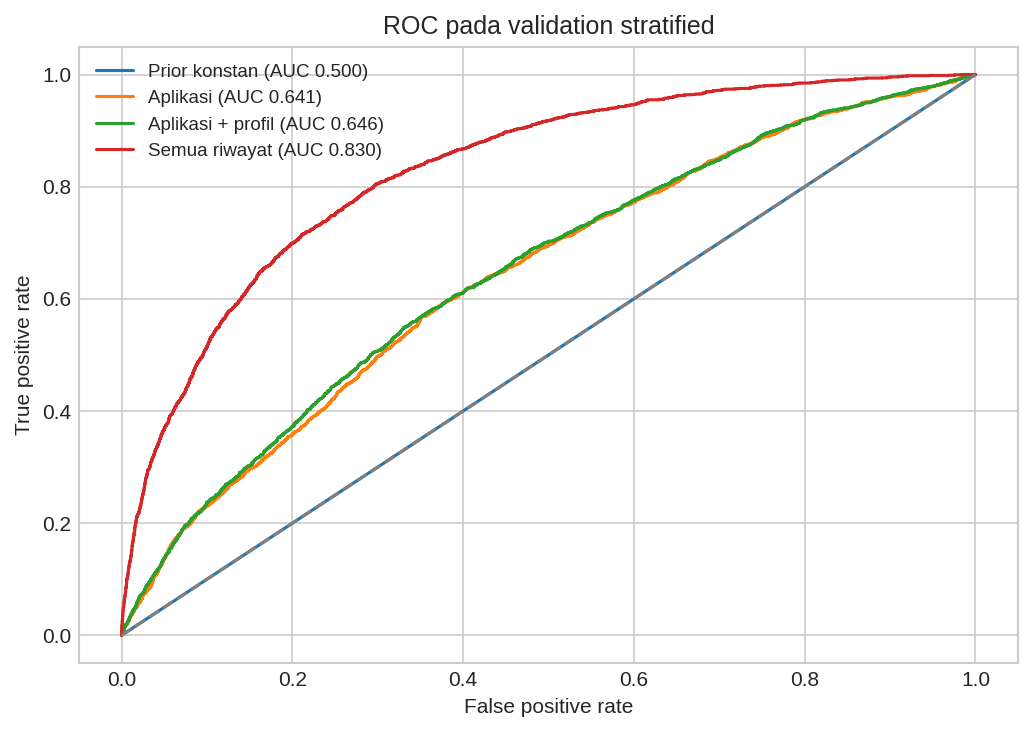

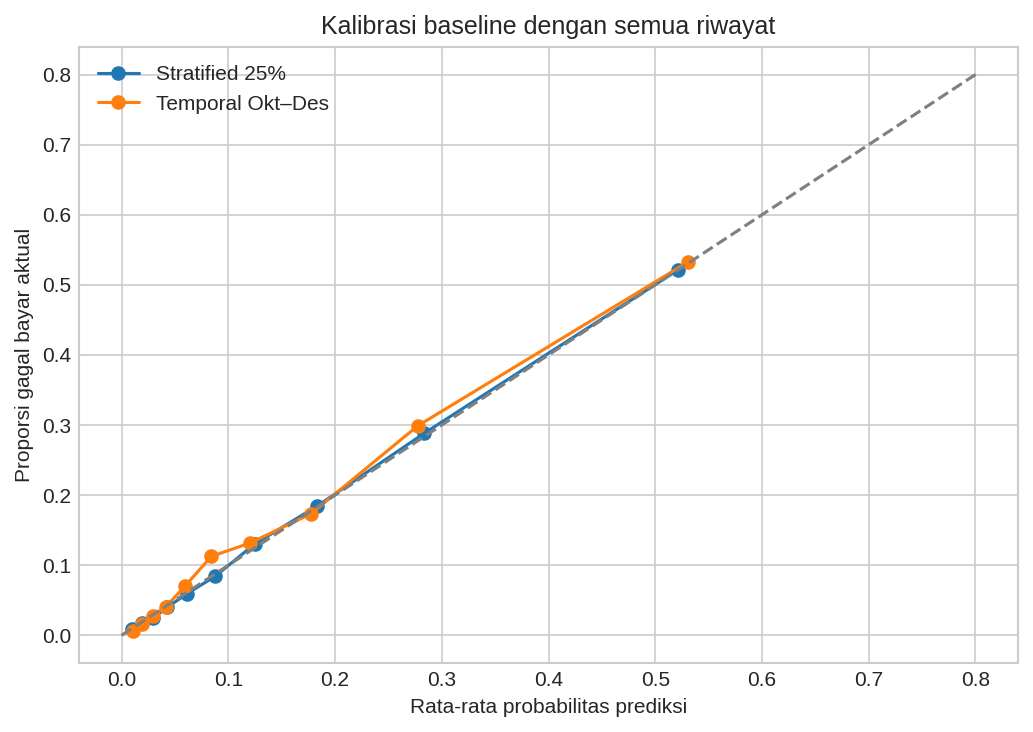

,feature,gain_importance
0,repayment_late_share,0.127896
1,repayment_historical_dpd_mean,0.078925
2,repayment_dpd30_share,0.045815
3,ecom_spend_90d,0.044621
4,ecom_last_purchase_recency_days,0.034682
5,repayment_paid_ratio,0.032579
6,bureau_score_min,0.027163
7,bureau_score_mean,0.025571
8,repayment_current_dpd_max,0.024209
9,bureau_score_max,0.023954


### Optimasi KS terbaru — validasi silang 3 fold

,ks,mean_fold_ks,roc_auc,average_precision
Baseline,0.492943,0.49455,0.826233,0.463545
Baru,0.511471,0.514915,0.836898,0.487471


{'extended/lgb_leaves31': 0.25, 'compact/cat_depth5': 0.75}

In [5]:
benchmark_path = ART / 'tables/model_benchmarks.csv'
if benchmark_path.exists() and summary['benchmarks']:
    display(pd.read_csv(benchmark_path))
    display(Image(filename=str(ART / 'figures/model_roc.png')))
    display(Image(filename=str(ART / 'figures/calibration.png')))
    display(pd.read_csv(ART / 'tables/feature_importance_gain.csv').head(20))
cv_path = ART / 'optimization/cross_validation_summary.json'
if cv_path.exists():
    cv = json.loads(cv_path.read_text())
    display(Markdown('### Optimasi KS terbaru — validasi silang 3 fold'))
    display(pd.DataFrame({'Baseline': cv['baseline'], 'Baru': cv['selected']}).T[['ks', 'mean_fold_ks', 'roc_auc', 'average_precision']])
    display(cv['selected']['recipe'])

## Pemeriksaan yang dapat dijalankan ulang

Assertion ini memeriksa integritas hasil, batas waktu, serta risiko salah urutan submission.

In [6]:
assert len(train) == 70000 and len(test) == 30000
assert features['application_id'].is_unique and features['customer_id'].is_unique
assert set(train['customer_id']).isdisjoint(test['customer_id'])
assert train['target'].isin([0, 1]).all() and test['target'].isna().all()
assert audit['submission']['same_id_set_as_test']
for checks in audit.values():
    for name, value in checks.items():
        if name.endswith('_at_or_after_cutoff') or name == 'incomplete_month_at_cutoff':
            assert value == 0, (name, value)
print('Integritas dasar dan batas waktu: OK')

Integritas dasar dan batas waktu: OK


## Template penyusunan submission

Isi `predictions` dengan probabilitas model yang Anda latih. Join dengan validasi one-to-one; kode template tidak mengirim submission.

In [7]:
def align_submission(predictions):
    sample = pd.read_csv(ROOT / 'data/raw/sample_submission.csv')
    assert predictions['application_id'].is_unique
    assert set(predictions['application_id']) == set(test['application_id'])
    result = sample[['application_id']].merge(
        predictions[['application_id', 'default_probability']],
        on='application_id', how='left', validate='one_to_one', sort=False
    )
    assert result['application_id'].equals(sample['application_id'])
    assert result['default_probability'].notna().all()
    assert result['default_probability'].between(0, 1).all()
    return result

## Laporan lengkap

Buka `artifacts/laporan_analisis.html` untuk laporan dengan seluruh grafik; CSV lengkap tersedia di `artifacts/tables/`.

Reproduksi dari terminal: `python scripts/analyze.py --reuse-features`. Untuk membangun agregasi ulang, hilangkan `--reuse-features`.